# 28. '온도 교란 구간' 규칙 점검 — ① 오경보 빈도 ② RG3 재현

**규칙 (사전 고정)** — 방향은 26번 R1 결과(호퍼온도↑·금형온도↓), 임계값은 라벨 없이 정상 기준(unlabeled)에서
- 샷 성분 = max(호퍼온도 추세 z, 0) + max(−금형온도 편차, 0) + 0.5 × max(호퍼온도 편차, 0)
- **구간 점수 E** = 같은 Run 최근 5샷 평균 (과거만 → 실시간 가능)
- 경보: E ≥ 정상 기준 E의 99% / 99.5% 분위수 (정상 생산에서 1% / 0.5%만 울리게)
- 에피소드: 같은 Run에서 연속 경보 묶음

**보는 것**
1. **오경보**: 정상 생산(unlabeled)·labeled 정상 Run에서 에피소드가 얼마나 자주 생기나, 불량 없는 에피소드가 몇 개인가
2. **RG3 재현**: RG3 가스도 주변 정상 대비 호퍼온도↑·금형온도↓인가, 구간 점수로 가스가 위에 오나
3. (사후 확인) CN7 R1에서 미성형 몇 샷 전에 경보가 울렸나 — 규칙을 R1에서 만들었으므로 증거가 아님

In [1]:
import os
import pandas as pd
from thermal_episode import (prepare, false_alarm_table, run_breakdown, ranking, lead_time, matched_compare,
                             episodes, plot_runs)
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 30)
OUT = './outputs/thermal_episode'
os.makedirs(OUT, exist_ok=True)

LAB, REF, TH = {}, {}, {}
for p in ['cn7', 'rg3']:
    LAB[p], REF[p], TH[p] = prepare(p)
    print(p.upper(), '임계값:', {q: round(t, 3) for q, t in TH[p].items()}, f'| 정상기준 {len(REF[p]):,}샷')

CN7 임계값: {0.99: 4.397, 0.995: 4.681} | 정상기준 5,179샷
RG3 임계값: {0.99: 4.093, 0.995: 5.019} | 정상기준 4,359샷


## 1. 오경보 빈도

In [2]:
FA = pd.concat([false_alarm_table(p, LAB[p], REF[p], TH[p]) for p in ['cn7', 'rg3']], ignore_index=True)
FA.to_csv(f'{OUT}/false_alarm.csv', index=False, encoding='utf-8-sig')
display(FA.round(4))

,제품,q,임계값 E,정상기준 경보 비율,정상기준 에피소드 수,"정상기준 1,000샷당 에피소드",labeled 정상 샷 경보 비율,labeled 에피소드 수,불량 포함 에피소드,불량 없는 에피소드(오경보),가스 경보/전체 가스,미성형계열 경보/전체
0,cn7,0.990,4.3970,0.0100,19,3.6687,0.0046,4,1,3,0/11,1/4
1,cn7,0.995,4.6813,0.0050,16,3.0894,0.0041,3,0,3,0/11,0/4
2,rg3,0.990,4.0933,0.0101,12,2.7529,0.0403,4,0,4,0/22,0/10
3,rg3,0.995,5.0194,0.0050,5,1.1471,0.0303,4,0,4,0/22,0/10


### 1-1. Run별 (q = 0.99)

In [3]:
RB = pd.concat([run_breakdown(p, LAB[p], TH[p]) for p in ['cn7', 'rg3']], ignore_index=True)
RB.to_csv(f'{OUT}/run_breakdown.csv', index=False, encoding='utf-8-sig')
display(RB.round(3))

,제품,Run,샷,가스,미성형계열,경보 샷,에피소드,가스 경보,정상 샷 경보 비율
0,cn7,cn7_R1,188,11,3,9,3,0,0.046
1,cn7,cn7_R2,418,0,0,0,0,0,0.000
2,cn7,cn7_R3,309,0,0,0,0,0,0.000
3,cn7,cn7_R4,189,0,0,0,0,0,0.000
4,cn7,cn7_R5,407,0,0,0,0,0,0.000
5,cn7,cn7_R6,463,0,1,1,1,0,0.002
6,rg3,rg3_R1,41,0,0,8,1,0,0.195
7,rg3,rg3_R2,103,4,1,7,1,0,0.071
8,rg3,rg3_R3,197,6,4,0,0,0,0.000
9,rg3,rg3_R4,74,3,1,5,1,0,0.071


### 1-2. labeled 에피소드 목록 (q = 0.99) — 불량 포함 / 직후 불량 / 오경보

In [4]:
for p in ['cn7', 'rg3']:
    t = TH[p][0.99]
    ep = episodes(LAB[p].assign(al=LAB[p]['E'] >= t), 'al')
    print(p.upper(), f'에피소드 {len(ep)}개'); display(ep)

CN7 에피소드 4개


,run_id,시작 seq,끝 seq,길이(샷),구간 내 불량,구간 내 가스,직후 10샷 불량
0,cn7_R1,4,8,5,0,0,0
1,cn7_R1,10,12,3,0,0,0
2,cn7_R1,59,59,1,1,0,2
3,cn7_R6,4,4,1,0,0,0


RG3 에피소드 4개


,run_id,시작 seq,끝 seq,길이(샷),구간 내 불량,구간 내 가스,직후 10샷 불량
0,rg3_R1,7,14,8,0,0,0
1,rg3_R2,4,10,7,0,0,0
2,rg3_R4,9,13,5,0,0,1
3,rg3_R6,7,10,4,0,0,5


## 2. 순위 성능 — 구간 점수 E로 가스가 위에 오나 (AP vs 기준선)

In [5]:
display(pd.DataFrame([ranking(p, LAB[p]) for p in ['cn7', 'rg3']]).round(3))

,제품,불량률,AP(전체 불량),AP_가스,가스 기준선(비율),Run별 상위10%_가스,AP_미성형,미성형 기준선(비율),Run별 상위10%_미성형
0,cn7,0.008,0.084,0.046,0.006,3/11,0.079,0.002,3/4
1,rg3,0.051,0.079,0.054,0.036,4/22,0.035,0.017,2/10


## 3. 시간 맞춘 비교 (모든 Run, 가스 vs 앞뒤 ±10샷 정상)
CN7은 26번과 같은 방향인지 재확인, **RG3에서도 호퍼온도↑·금형온도↓(δ 부호 같음)면 재현**

In [6]:
MC = pd.concat([matched_compare(LAB[p]).assign(제품=p) for p in ['cn7', 'rg3']], ignore_index=True)
MC.to_csv(f'{OUT}/matched_compare.csv', index=False, encoding='utf-8-sig')
display(MC.round(3))

,불량,변수,n불량,n주변정상,불량 중앙값,주변정상 중앙값,Cliff's δ,p,q(BH),제품
0,가스,호퍼온도 추세,11,40,0.020,-0.002,0.755,0.000,0.001,cn7
1,가스,호퍼온도,11,40,3.000,0.000,0.620,0.002,0.004,cn7
2,가스,금형온도,11,40,-1.000,0.000,-0.534,0.006,0.008,cn7
3,가스,호퍼온도 상승량,11,40,0.320,0.020,0.600,0.002,0.004,cn7
4,가스,금형온도 상승량,11,40,0.180,0.180,0.077,0.698,0.698,cn7
5,가스,금형온도 추세,11,40,0.004,0.006,-0.264,0.188,0.219,cn7
6,가스,구간 점수 E,11,40,2.461,0.699,0.693,0.000,0.002,cn7
7,가스,호퍼온도 추세,22,276,-0.003,0.001,-0.015,0.909,0.909,rg3
8,가스,호퍼온도,21,269,0.000,0.000,-0.025,0.849,0.909,rg3
9,가스,금형온도,21,269,1.000,0.000,0.238,0.066,0.459,rg3


## 4. (사후 확인) CN7 R1 — 첫 미성형 몇 샷 전에 경보가 울렸나

In [7]:
cn = LAB['cn7']
r1 = cn[cn['group'] == '미성형계열']['run_id'].mode()[0]
for q in [0.99, 0.995]:
    print(q, lead_time(cn, TH['cn7'], q=q, run=r1))

0.99 {'첫 미성형 seq': 59, '그 전 30샷 중 첫 경보 seq': None, '선행 샷 수': None}
0.995 {'첫 미성형 seq': 59, '그 전 30샷 중 첫 경보 seq': None, '선행 샷 수': None}


## 5. Run별 구간 점수 흐름

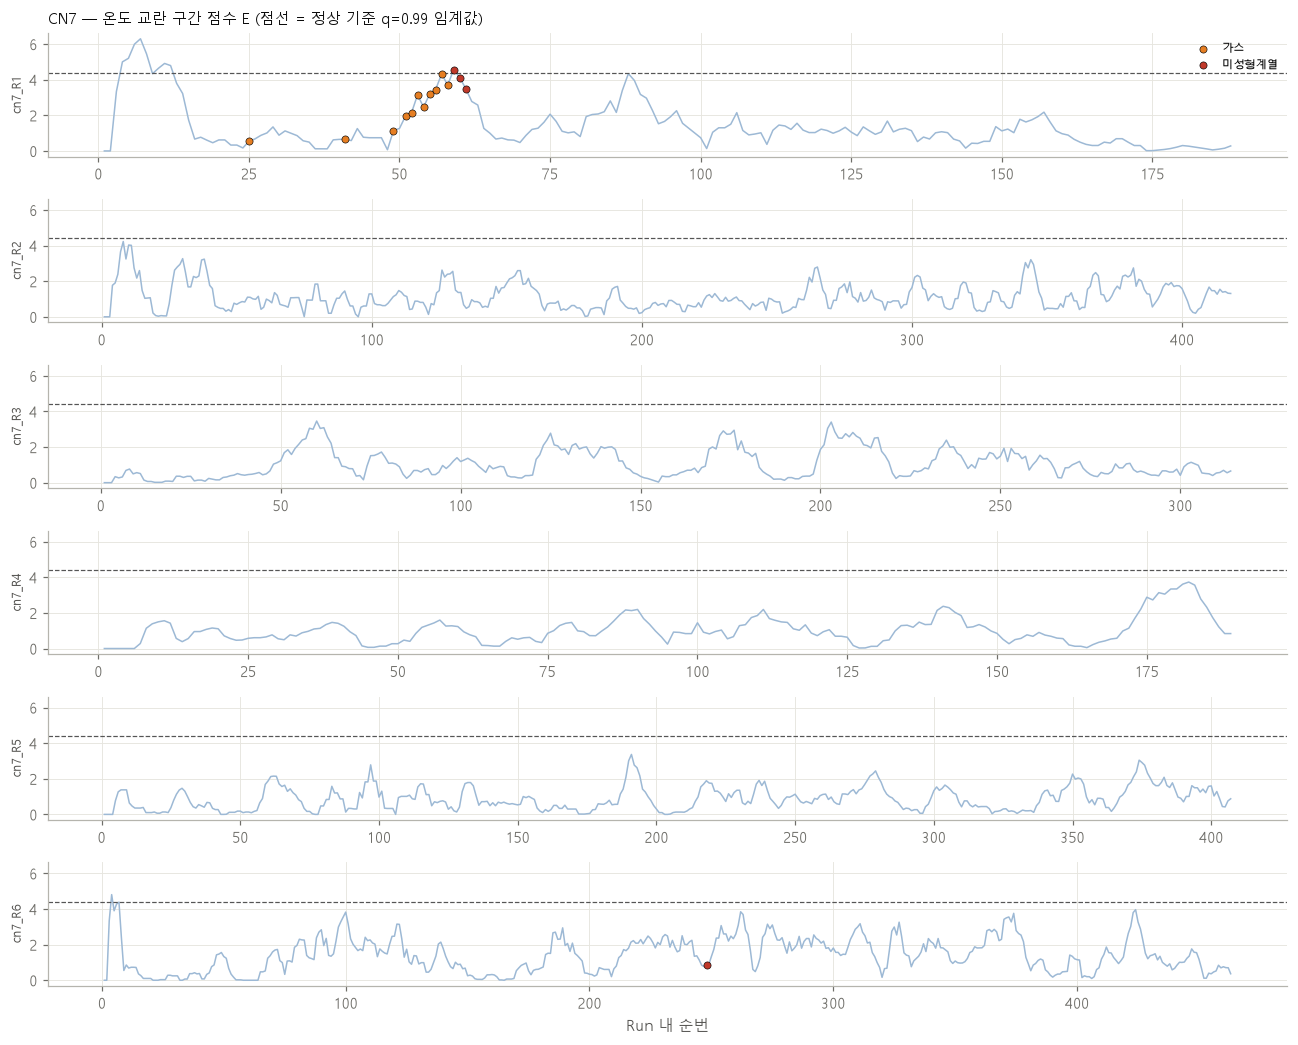

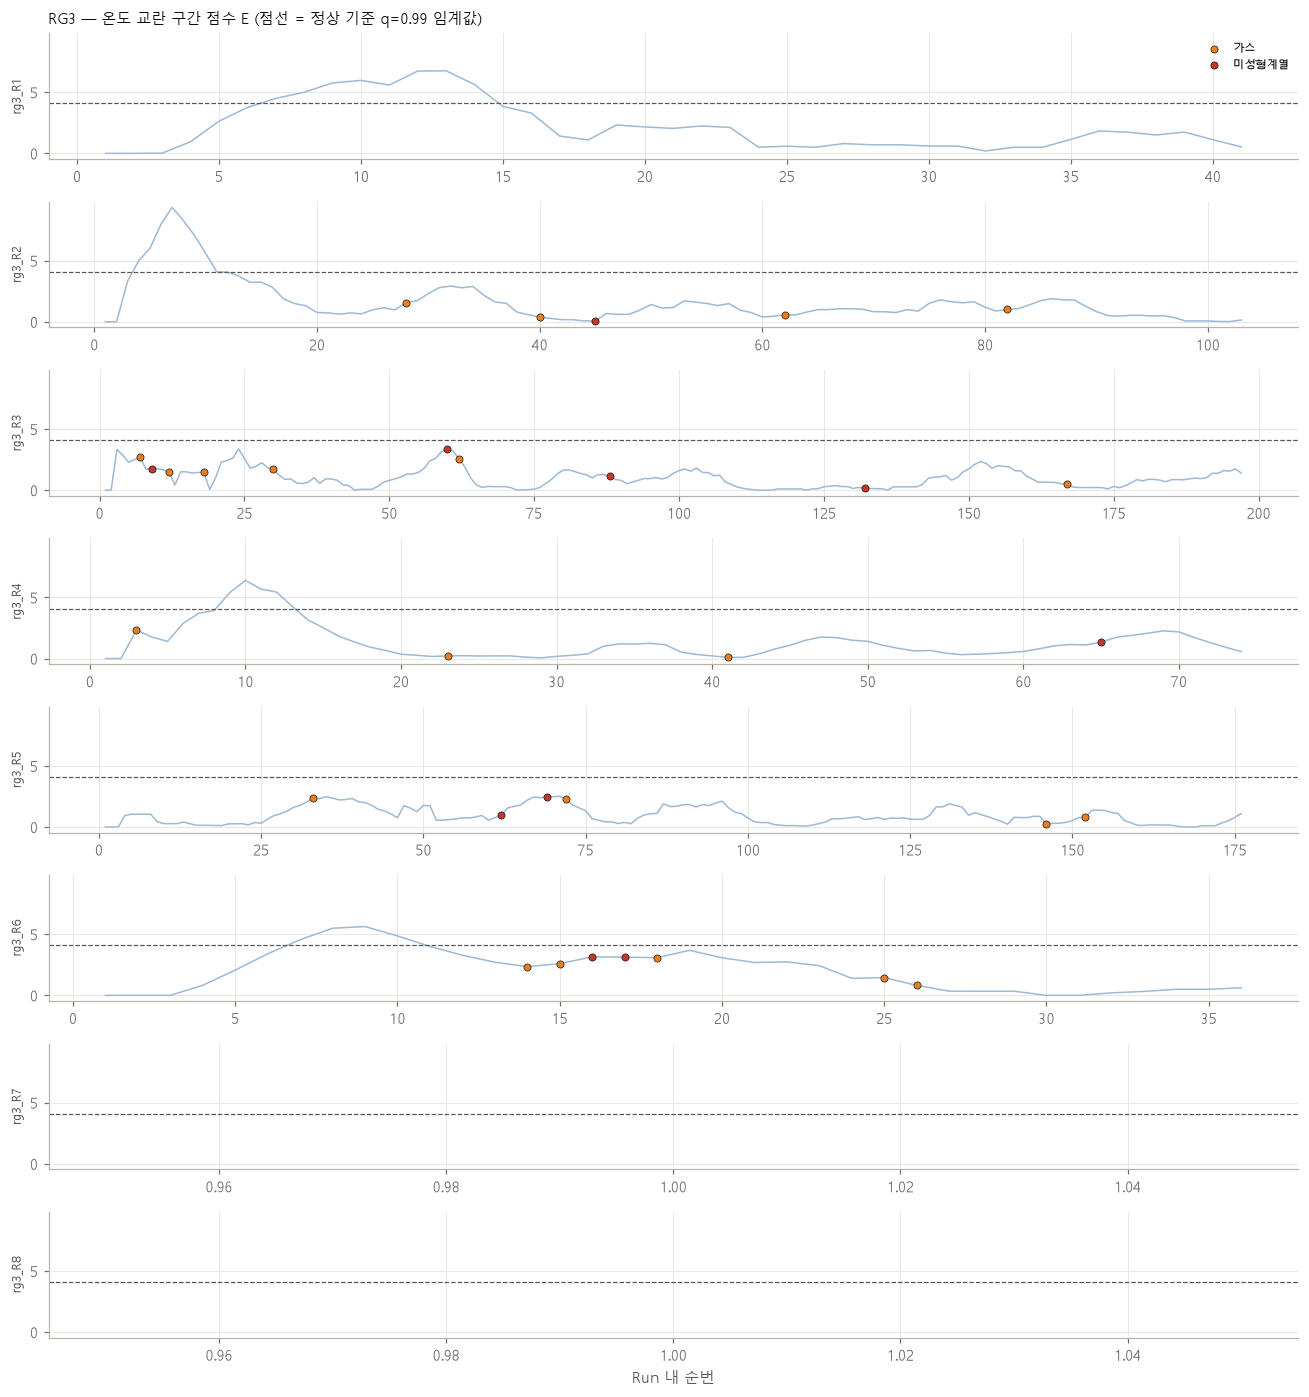

In [8]:
for p in ['cn7', 'rg3']:
    plot_runs(p, LAB[p], TH[p], save=f'{OUT}/E_runs_{p}.png')

## 해석 가이드
| 결과 | 판단 |
|---|---|
| 정상기준 에피소드가 1,000샷당 수 개 이하 + labeled 정상 Run에서 오경보 에피소드가 거의 없음 | 현장에서 쓸 만한 빈도 |
| 오경보 에피소드가 불량 에피소드보다 훨씬 많음 | 규칙이 너무 흔하게 울림 → 단독 사용 불가 |
| RG3 가스에서 δ 부호가 CN7과 같고 AP가 기준선보다 뚜렷이 높음 | 재현 → 4장 '구간 경보' 제안 근거 강화 |
| RG3에서 방향이 다르거나 AP ≈ 기준선 | CN7 R1 한 번의 현상 → 가설로만 언급 |